In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan

import sys 
sys.path.append('../Code/')
import modules as mod




In [5]:
def plot_rectangle_module(M): 
    ## add coordinates of corners!!
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ## rectangles 
    list_rectanlges = M.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)

    plt.xlim([-3, 15])
    plt.ylim([-3, 15])

    plt.title('Rectangle module')  
    plt.show()
    
def plot_rectangle_modules(M,N): 
    ## add coordinates of corners!!
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ## rectangles 
    list_rectanlges = M.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)
    list_rectanlges = N.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)

    plt.xlim([-3, 15])
    plt.ylim([-3, 15])

    plt.title('Rectangle module')  
    plt.show()
    
def closure_lub(Points): 
        """ Find the closure under least upper boud of the critical points"""
        ## Todo: check that it works properly on an example
        ## Not the most efficient way to code this function 
    
        l = len(Points)
        for i in range(l): 
            p = Points[i]
            for j in range(i+1, l): 
                q = Points[j]
                if not mod.are_comparable(p,q):
                    lub = (max(p[0],q[0]), max(p[1],q[1]))
                    Points.append(lub)

        return list(set(Points))
    
def plot_weighted_bottleneck(M,N): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    C = list(set(Crit_M+Crit_N))
    Crit_MN = closure_lub(C)
    #print(len(Crit_MN))
    #Crit_MN=list(set(Crit_M+Crit_N))
    Lines = []
    DD = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                DD.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    print('Maximum distance for lines:')
    print(max(DD))
    
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,100)[1:-1]
    B = np.linspace(-5,5,100)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    val = max(Dist)
    idx = Dist.index(val)
    print('Maximum distance computed:')
    print(max(Dist))     
    plt.figure(figsize=(8,8))
    plt.scatter(T, BB, c= Dist,s = 10, cmap = "summer")
    plt.scatter(T[idx], BB[idx], marker = 'x', color = 'red')
    print(T[idx])
    print(BB[idx])
    
    ## plot markers for the lines through critical points
    b_crit = []
    theta_crit = []
    for j in range(len(Lines)):
        Line = Lines[j]
        b= Line.b[0]
        theta = atan(Line.m[1]/Line.m[0])
        b_crit.append(b)
        theta_crit.append(theta)
    
    for j in range(len(Lines)): 
        plt.scatter(theta_crit[j], b_crit[j], marker = 'x', color = 'grey')
        #plt.text(theta_crit[j], b_crit[j], str(Crit[j]))
    val = max(DD)
    idx=DD.index(val)
    plt.scatter(theta_crit[idx], b_crit[idx], marker = 'x', color = 'black')
    ## plot titles
    plt.xlabel('theta')
    plt.ylabel('b')
    plt.title("Weighted bottleneck distance as a function of theta and b")
    plt.colorbar(label="Weighted distance", orientation="horizontal")
    plt.clim(0,max(Dist))
    plt.show()
    



In [31]:
def compute_weighted_bottleneck_distances(M,N): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    C = list(set(Crit_M+Crit_N))
    Crit_MN = closure_lub(C)
    #print(len(Crit_MN))
    #Crit_MN=list(set(Crit_M+Crit_N))
    Lines = []
    DD = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                DD.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    print('Maximum distance for lines:')
    print(max(DD))
    
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,100)[1:-1]
    B = np.linspace(-5,5,100)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    val = max(Dist)
    idx = Dist.index(val)
    print('Maximum distance computed:')
    print(max(Dist))     
    print(T[idx])
    print(BB[idx])
    
    s = sin(T[idx])
    c = cos(T[idx])
    maxm = max(s,c)
    L_max = mod.Line((c/maxm, s/maxm), (BB[idx],-BB[idx]))
    return T,BB, idx, L_max


### Example 1: 
the modules $M = (2,2), (7,10)$ and $N = (2,2), (7,7)$ 
* maximum bottleneck distance computed for lines through **2**  critical points is $1.87$
* maximum bottleck is attained at the **diagonal** line through $(7,10)$  


In [32]:
T, BB, idx, L_max = compute_weighted_bottleneck_distances(M,N)

There are 2 lines through critical points
Maximum distance for lines:
1.8749999999999996
Maximum distance computed:
2.5
0.7933314781792408
-1.3636363636363638


In [33]:
print(L_max.m)
print(L_max.b)

(0.9842579269999706, 1.0)
(-1.3636363636363638, 1.3636363636363638)


In [30]:
BB[idx]

-1.3636363636363638

In [ ]:
L_max

In [14]:
rect_m1 = mod.Rectangle((2,2),(7,10),1)
M = mod.RectangleModule([rect_m1])
rect_n1 = mod.Rectangle((2,2),(7,7),1)
N= mod.RectangleModule([rect_n1])


There are 2 lines through critical points
Maximum distance for lines:
1.8749999999999996
Maximum distance computed:
2.5


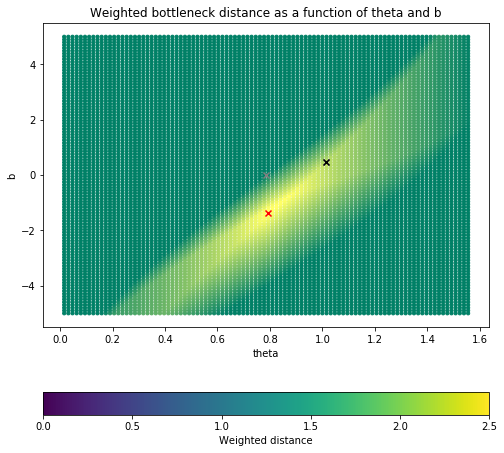

In [20]:
plot_weighted_bottleneck(M,N)

In [16]:
T, BB, idx, L_max = compute_weighted_bottleneck_distances(M,N)

There are 2 lines through critical points
Maximum distance for lines:
1.8749999999999996
Maximum distance computed:
2.5
0.7933314781792408
-1.3636363636363638


In [18]:
L_max.b

(-1.3636363636363638, 1.3636363636363638)

In [19]:
L_max.m

(0.01586796117199151, 1.0)

In [24]:
L = mod.Line((1,1),(7,10))

In [28]:
mod.compute_weighted_bottleneck(M,N,L)

2.5

In [27]:
L.b

(-1.5, 1.5)

## Example 2 

In [34]:
rect_m1 = mod.Rectangle((0,-1),(7,6),1)
rect_m2 = mod.Top_infinite_rectangle((0,3),(7,3),1)
M = mod.RectangleModule([rect_m1,rect_m2])
rect_n1 = mod.Top_infinite_rectangle((0,-1),(7,-1),1)
rect_n2 = mod.Rectangle((0,3),(7,6),1)
N= mod.RectangleModule([rect_n1,rect_n2])

In [35]:
T, BB, idx, L_max = compute_weighted_bottleneck_distances(M,N)

TypeError: 'float' object is not subscriptable